# High Multicollinearity Experiment (n >> p)

## 0. Imports

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Import data generation
from data_generation.generate_data import generate_data

# Import plots
from plots.coefficient_plot import coefficient_plot
from plots.metrics import compute_metrics

# Import models
from models.OLS import run_ols
from models.LASSO import run_lasso, run_lasso_cv
from models.Ridge import run_ridge, run_ridge_cv
from models.ElasticNet import run_elasticnet_alpha, run_elasticnet_l1ratio, run_elasticnet_cv

# Removing Warnings
import warnings


In [32]:
warnings.filterwarnings('ignore')

## 1. Generating Data

GENERATED DATA:
Shape of X: (150, 50)

X Matrix: 
 [[ 0.00959301  0.02000724  0.01686174 ...  0.00120537 -0.01649362
   0.04271408]
 [-0.02958021 -0.00436776 -0.01035954 ...  0.00648551  0.01579155
   0.00436303]
 [ 0.01259495 -0.02383541 -0.0026646  ...  0.01598071 -0.01104271
  -0.00793164]
 ...
 [-0.00555506  0.00857587 -0.0005051  ... -0.00410612  0.00449764
  -0.01638597]
 [-0.01907762  0.01567045 -0.00189618 ...  0.00761293  0.03148301
   0.0151361 ]
 [ 0.0311618  -0.00530682  0.01119356 ... -0.03978743 -0.02468155
  -0.04675128]]
Shape of y: (150,)

y Vector: 
 [ 1.44161281 -1.68121076 -2.6834931   1.91549683 -0.62700179 -4.27001399
 -4.13142362 -2.14771719 -1.43011157  3.3664422  -0.46662664 -0.48434098
 -1.83207758 -4.00034185 -1.78830344 -0.89589014  1.54595706  3.13903613
  1.55664473 -2.41949241  3.67869701  1.48434706 -0.63019468 -1.81292209
  3.01519302  1.78575061  5.42462141  0.55830954  0.65241292 -0.09857502
 -0.5713218   0.84770952 -4.92492304 -1.5642933  -0.72700417

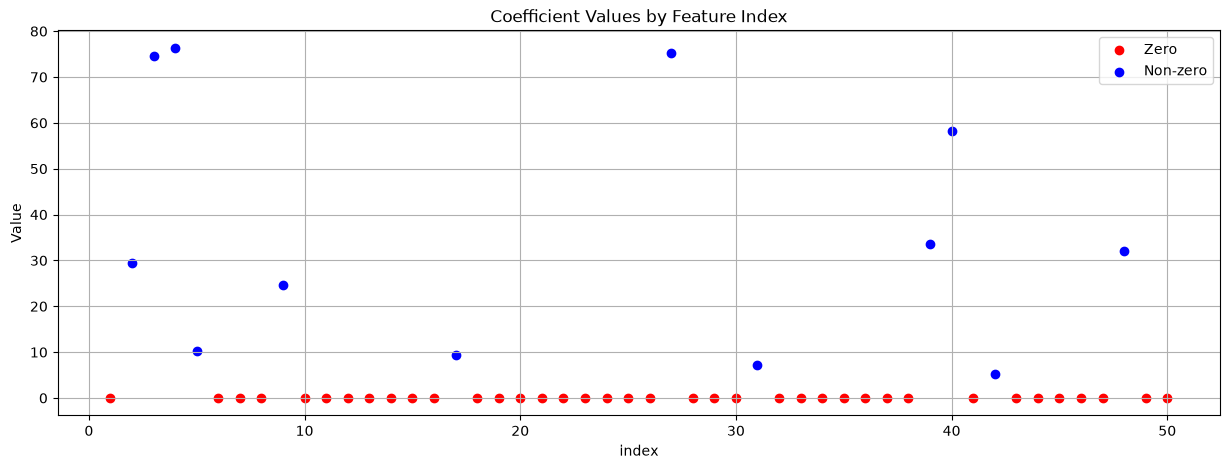

In [33]:
X_train, X_test, y_train, y_test, coef = generate_data(
    n_samples=150,
    n_features=50,
    n_informative=12,
    noise=0.0,
    effective_rank=5,
    tail_strength=0.1
)

coefficient_plot(coef)


## 2. Ordinary Least Square

MAE: 0.00
MSE: 0.00
RMSE: 0.00
R² Score: 1.00
Number of non zero coefs: 50
Max coef magnitude: 1.8942
Mean coef magnitude: 0.1848


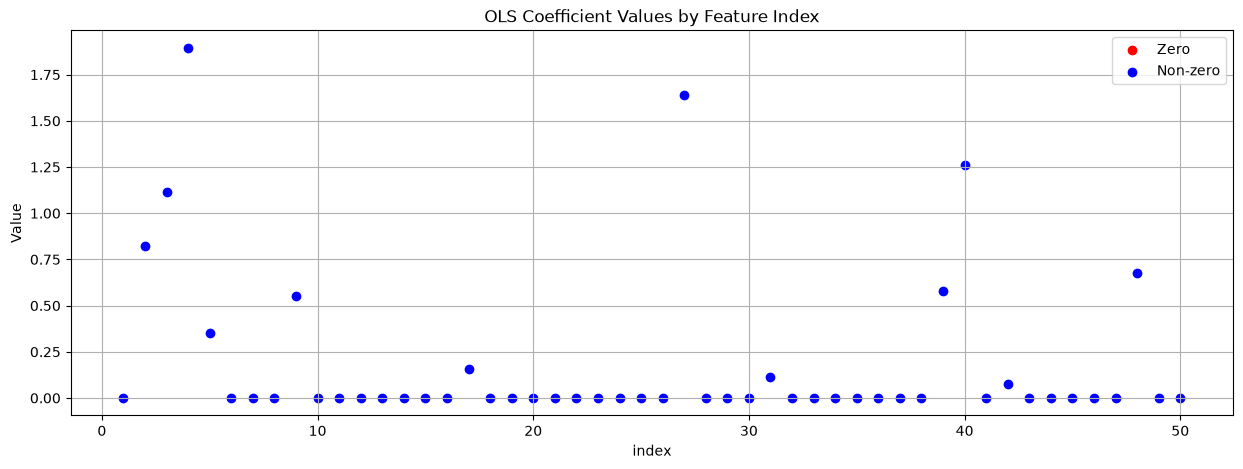

In [34]:
OLS_model = run_ols(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

## 3. Least Absolute Shrinkage and Selection Operator

Metrics for i = 0.001:
MAE: 0.01
MSE: 0.00
RMSE: 0.01
R² Score: 1.00
Number of non zero coefs: 23
Max coef magnitude: 1.8824
Mean coef magnitude: 0.1827


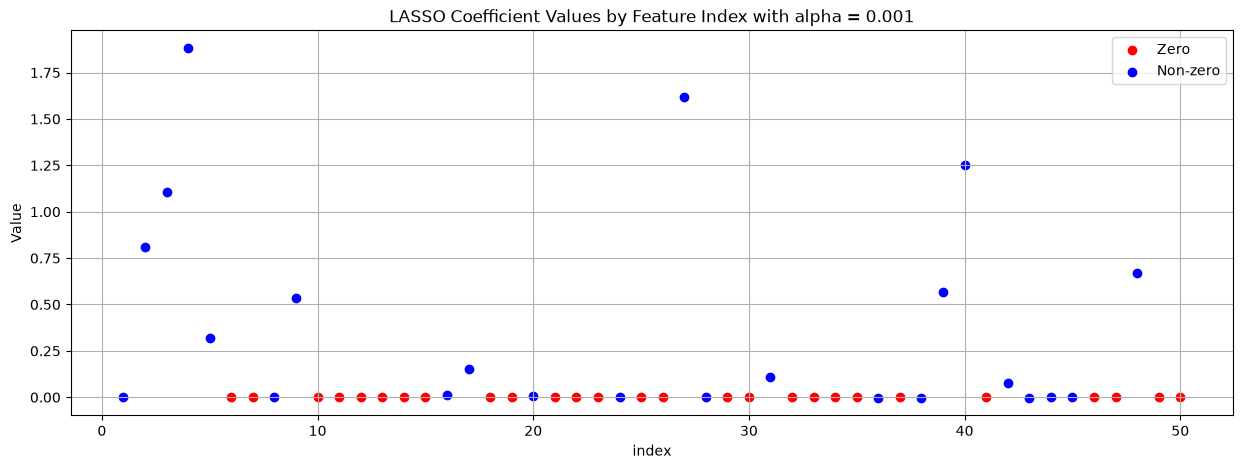

Metrics for i = 0.01:
MAE: 0.08
MSE: 0.01
RMSE: 0.11
R² Score: 1.00
Number of non zero coefs: 23
Max coef magnitude: 1.7727
Mean coef magnitude: 0.1634


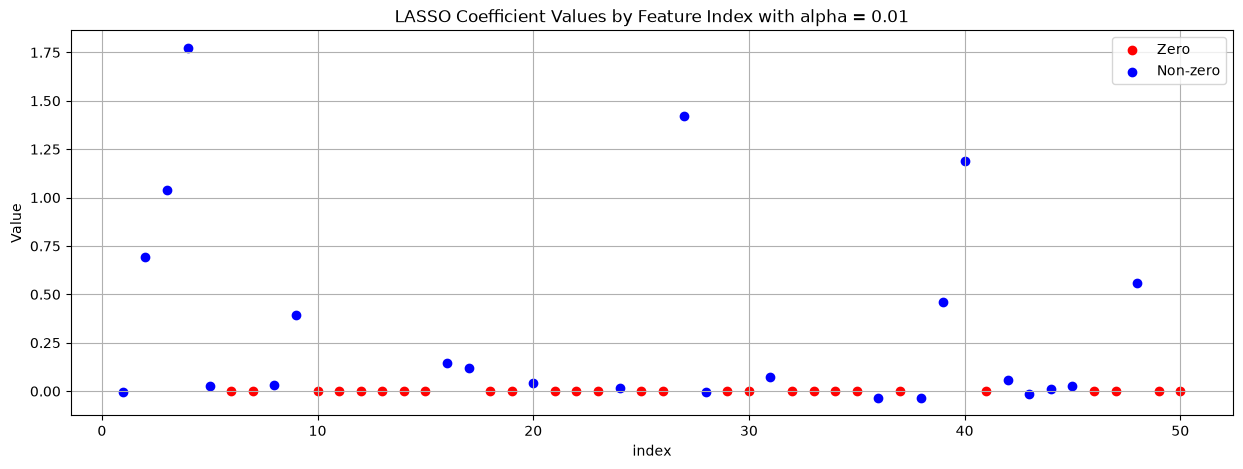

Metrics for i = 0.1:
MAE: 0.52
MSE: 0.44
RMSE: 0.66
R² Score: 0.89
Number of non zero coefs: 11
Max coef magnitude: 0.7918
Mean coef magnitude: 0.0667


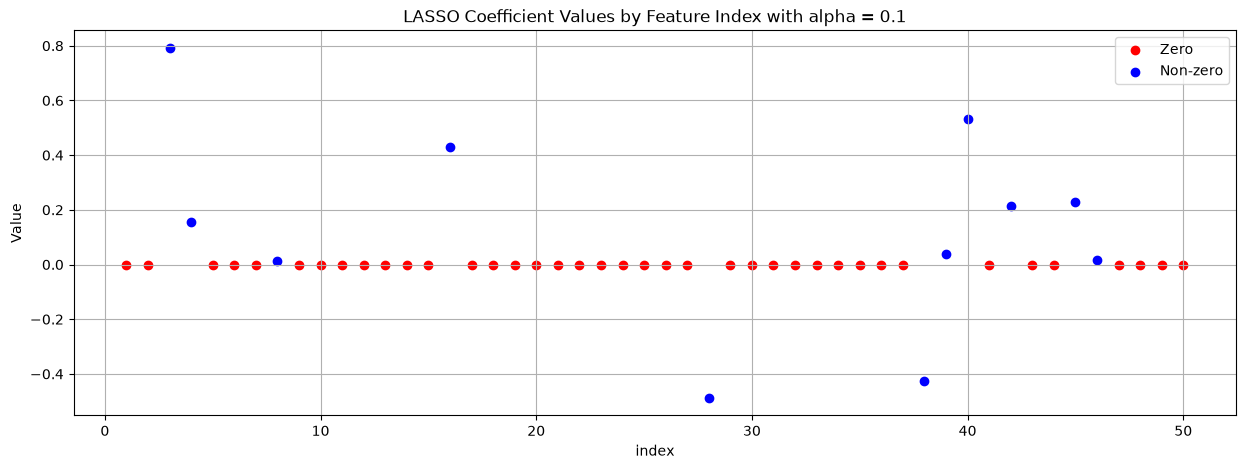

Metrics for i = 1.0:
MAE: 1.19
MSE: 2.49
RMSE: 1.58
R² Score: 0.37
Number of non zero coefs: 4
Max coef magnitude: 0.3883
Mean coef magnitude: 0.0163


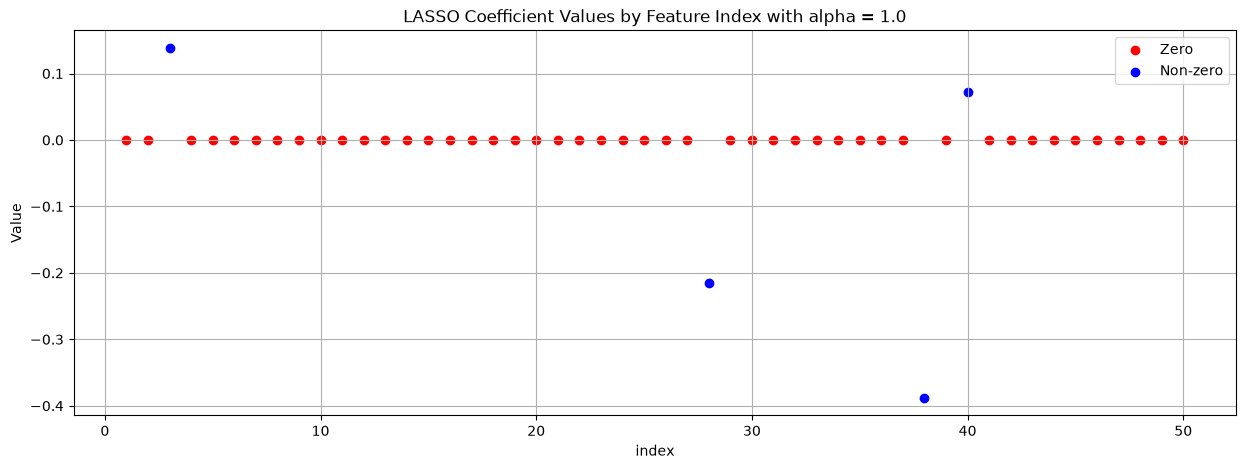

Metrics for i = 10.0:
MAE: 1.55
MSE: 4.41
RMSE: 2.10
R² Score: -0.11
Number of non zero coefs: 0
Max coef magnitude: 0.0000
Mean coef magnitude: 0.0000


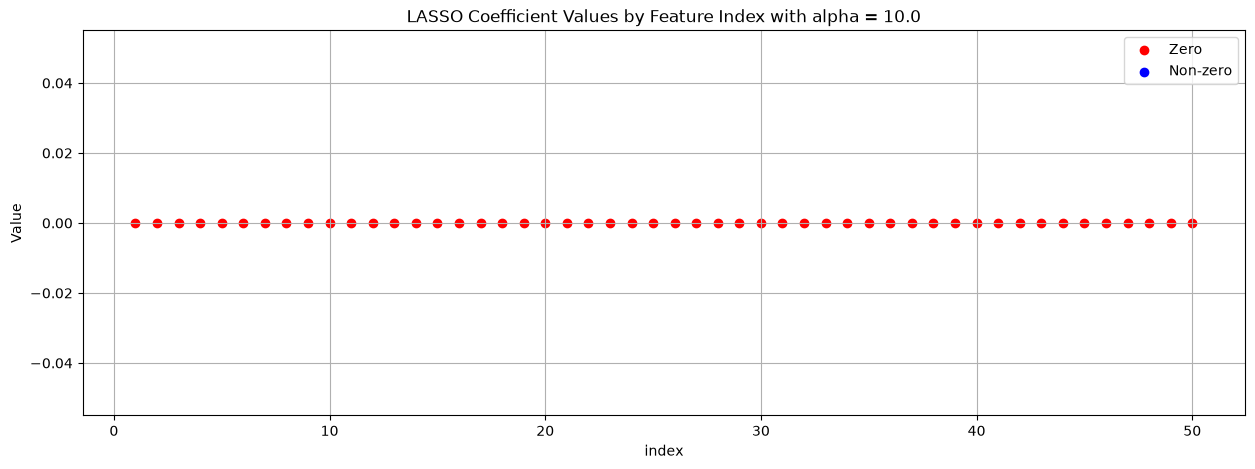

Metrics for i = 100.0:
MAE: 1.55
MSE: 4.41
RMSE: 2.10
R² Score: -0.11
Number of non zero coefs: 0
Max coef magnitude: 0.0000
Mean coef magnitude: 0.0000


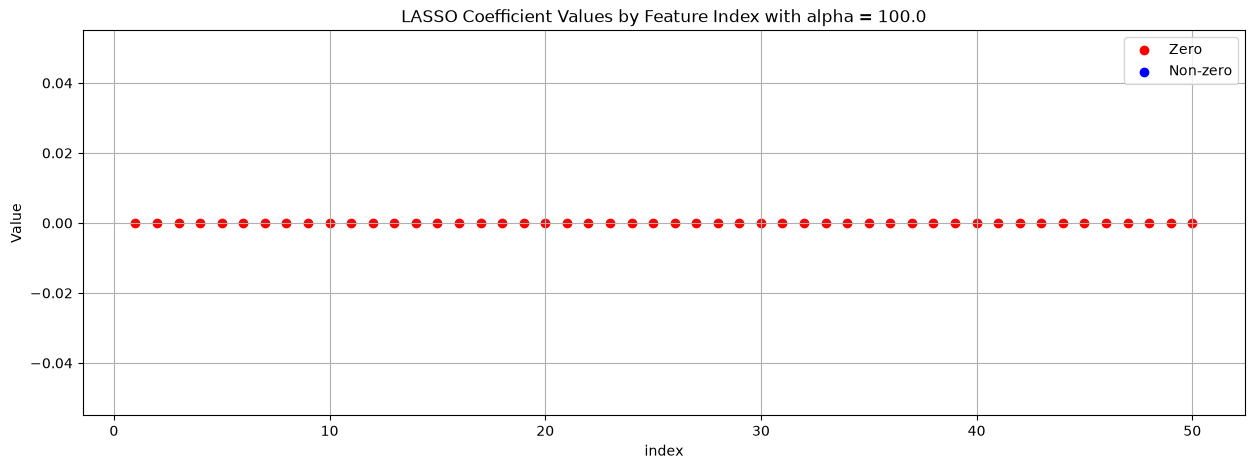

In [35]:
LASSO_models = run_lasso(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

### Best alpha for LASSO

MAE: 0.02
MSE: 0.00
RMSE: 0.03
R² Score: 1.00
Number of non zero coefs: 23
Max coef magnitude: 1.8630
Mean coef magnitude: 0.1793


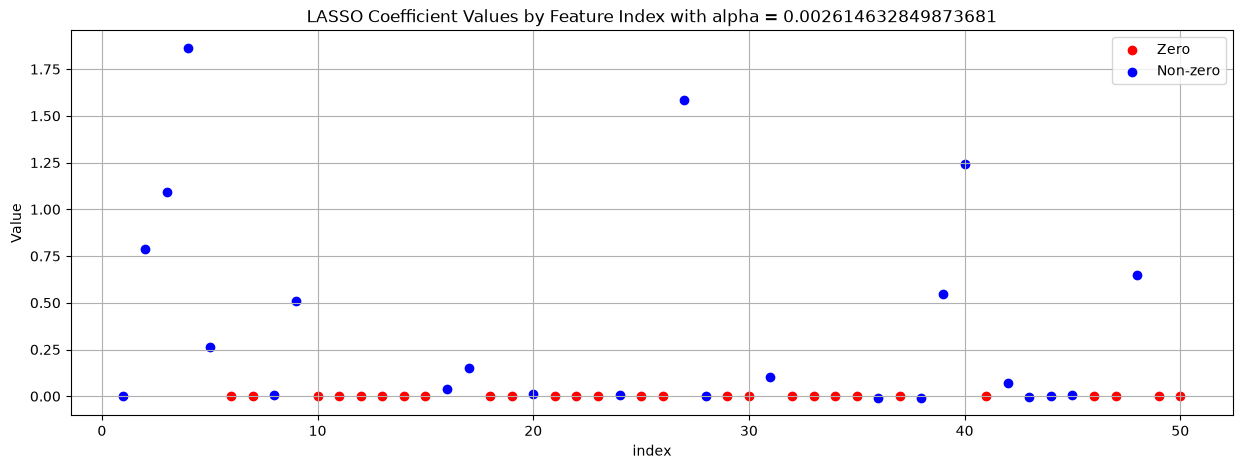

In [36]:
LASSOCV_model = run_lasso_cv(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

### Variable Selection via LASSO for Linear Regression

In this approach, LASSO select the features. Subsequently, an Ordinary Least Sqaures (OLS) regression is fitted on the selected subset of variables.

MAE: 0.02
MSE: 0.00
RMSE: 0.03
R² Score: 1.00
Number of non zero coefs: 23
Max coef magnitude: 1.8630
Mean coef magnitude: 0.1793


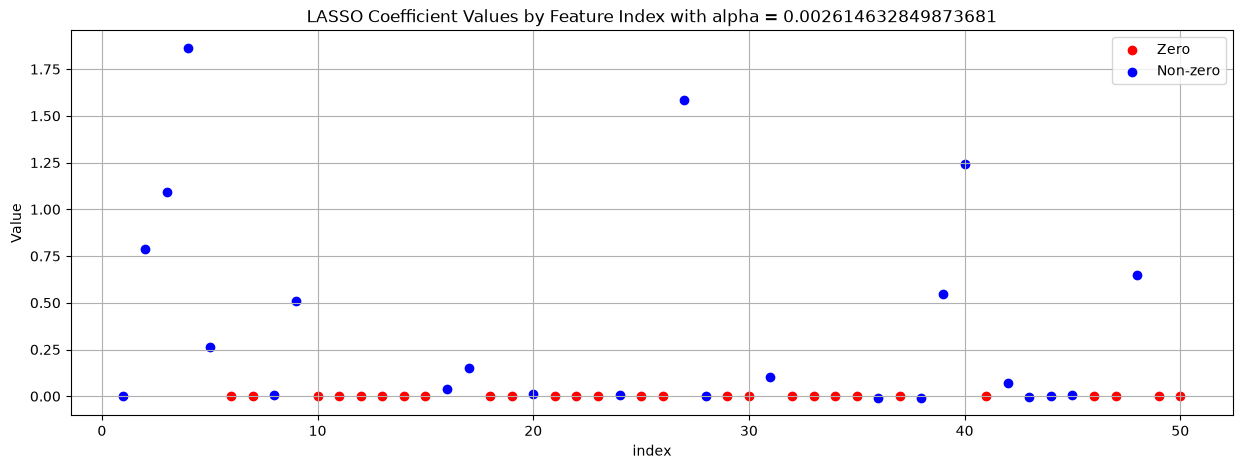

In [37]:
LASSOCV_model = run_lasso_cv(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

In [38]:
# printing Non-zero coefs
# np.nonzeros returns a tuple, [0] is the vector
nonzero = np.nonzero(LASSOCV_model.coef_.copy())[0]
for i in nonzero:
    print(f"idx: {i}, value: {LASSOCV_model.coef_[i]}")

idx: 0, value: -0.0008787824296048694
idx: 1, value: 0.7886916442804347
idx: 2, value: 1.095242719812344
idx: 3, value: 1.8630377839036052
idx: 4, value: 0.2655660596291386
idx: 7, value: 0.008059282302460703
idx: 8, value: 0.511261178805574
idx: 15, value: 0.037880564197299335
idx: 16, value: 0.1484151201249869
idx: 19, value: 0.011656429902855734
idx: 23, value: 0.004148149328715091
idx: 26, value: 1.5822854626783094
idx: 27, value: -0.000949145623036286
idx: 30, value: 0.10342275313878944
idx: 35, value: -0.009446026972972567
idx: 37, value: -0.0089341496532549
idx: 38, value: 0.5483992482110306
idx: 39, value: 1.2408504836475398
idx: 41, value: 0.07218528748029837
idx: 42, value: -0.004079287124564295
idx: 43, value: 0.0034144715217741092
idx: 44, value: 0.005855915846080256
idx: 47, value: 0.6482578019627623


In [39]:
# filtering the columns
X_train_nonzero = X_train[:, nonzero]
X_test_nonzero = X_test[:, nonzero]

MAE: 0.00
MSE: 0.00
RMSE: 0.00
R² Score: 1.00
Number of non zero coefs: 23
Max coef magnitude: 1.8942
Mean coef magnitude: 0.4018


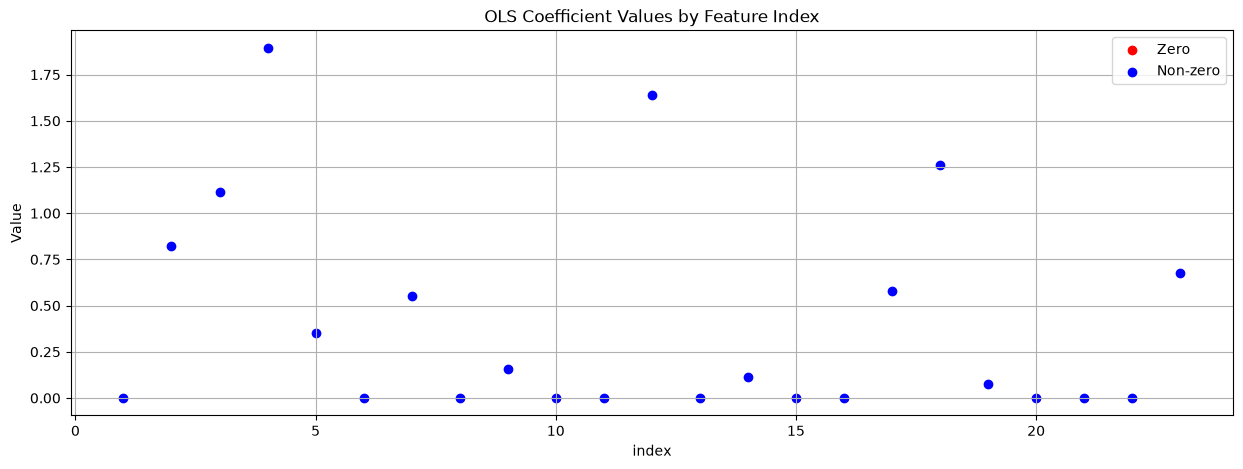

In [40]:
# training the model based on features whose coefficient is nonzero
OLS_model = run_ols(X_train_nonzero, X_test_nonzero, y_train, y_test, compute_metrics, coefficient_plot)

## 4. Ridge

Metrics for i = 0.001:
MAE: 0.00
MSE: 0.00
RMSE: 0.00
R² Score: 1.00
Number of non zero coefs: 50
Max coef magnitude: 1.8937
Mean coef magnitude: 0.1849


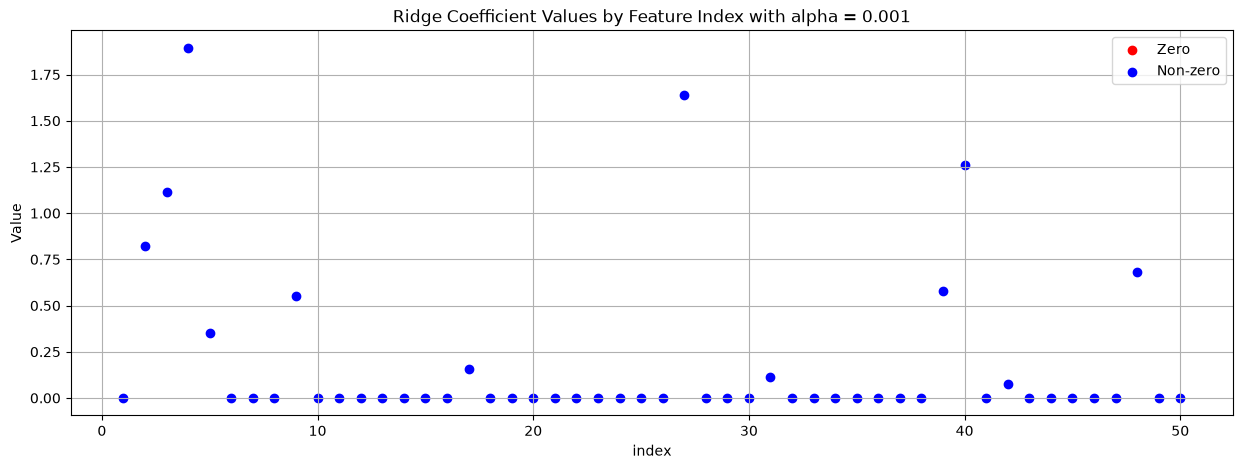

Metrics for i = 0.01:
MAE: 0.00
MSE: 0.00
RMSE: 0.00
R² Score: 1.00
Number of non zero coefs: 50
Max coef magnitude: 1.8892
Mean coef magnitude: 0.1850


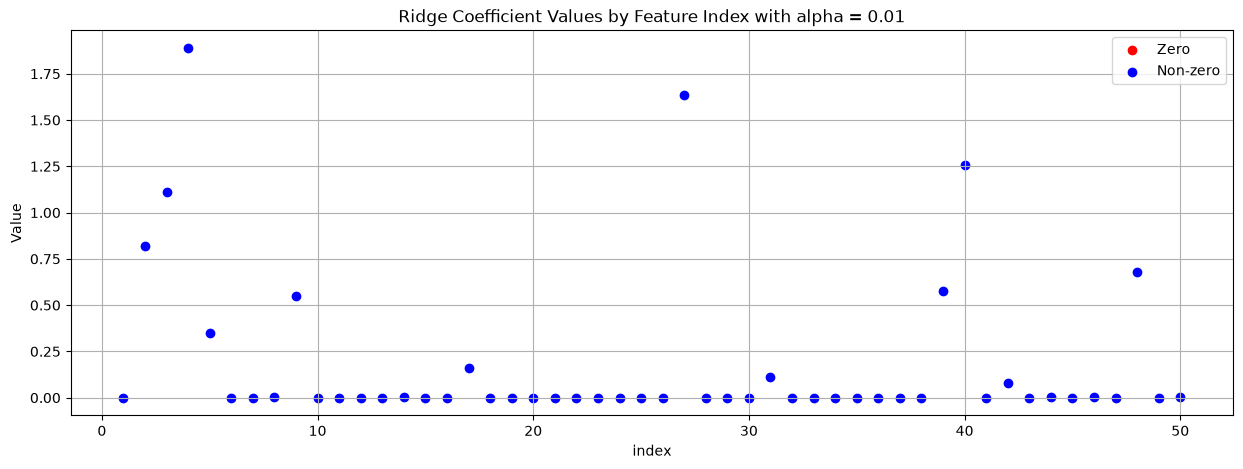

Metrics for i = 0.1:
MAE: 0.02
MSE: 0.00
RMSE: 0.02
R² Score: 1.00
Number of non zero coefs: 50
Max coef magnitude: 1.8456
Mean coef magnitude: 0.1860


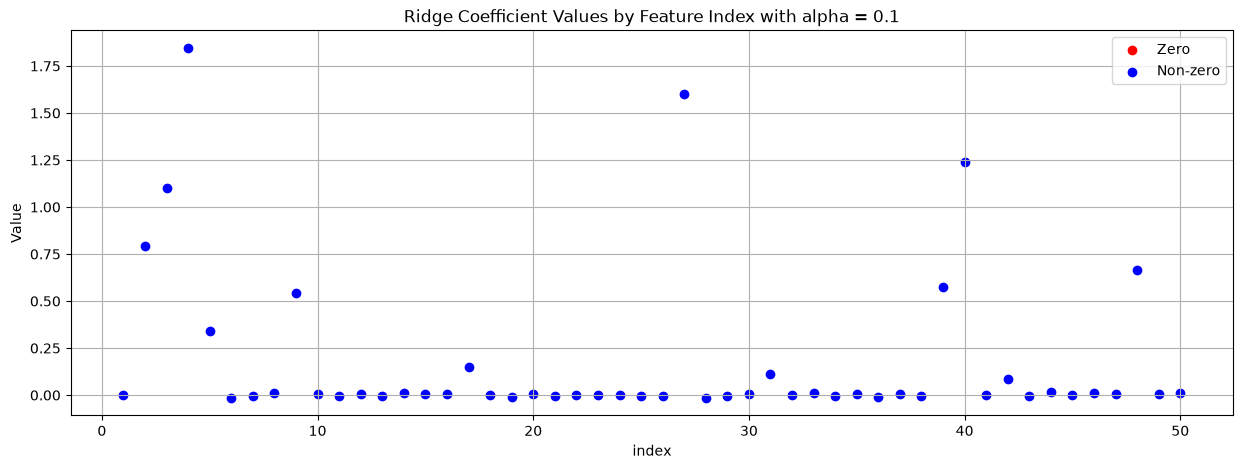

Metrics for i = 1.0:
MAE: 0.12
MSE: 0.02
RMSE: 0.15
R² Score: 0.99
Number of non zero coefs: 50
Max coef magnitude: 1.5197
Mean coef magnitude: 0.1864


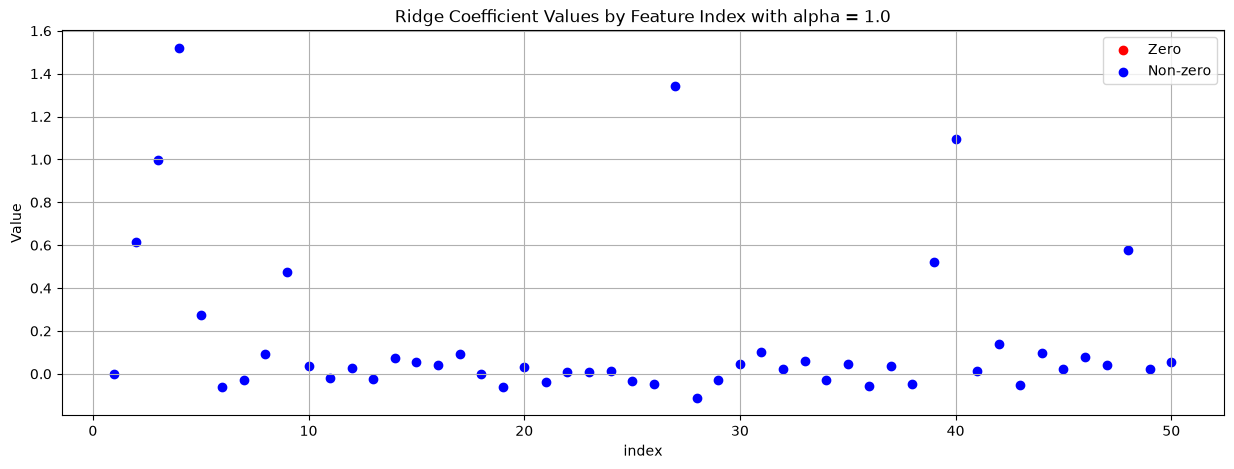

Metrics for i = 10.0:
MAE: 0.38
MSE: 0.21
RMSE: 0.46
R² Score: 0.95
Number of non zero coefs: 50
Max coef magnitude: 0.6428
Mean coef magnitude: 0.1402


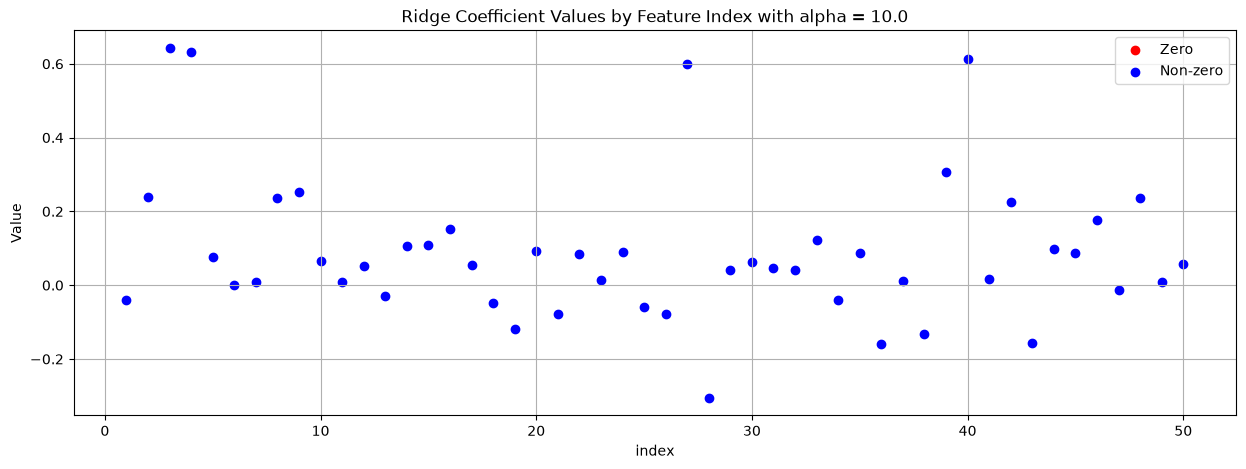

Metrics for i = 100.0:
MAE: 0.58
MSE: 0.52
RMSE: 0.72
R² Score: 0.87
Number of non zero coefs: 50
Max coef magnitude: 0.2929
Mean coef magnitude: 0.0827


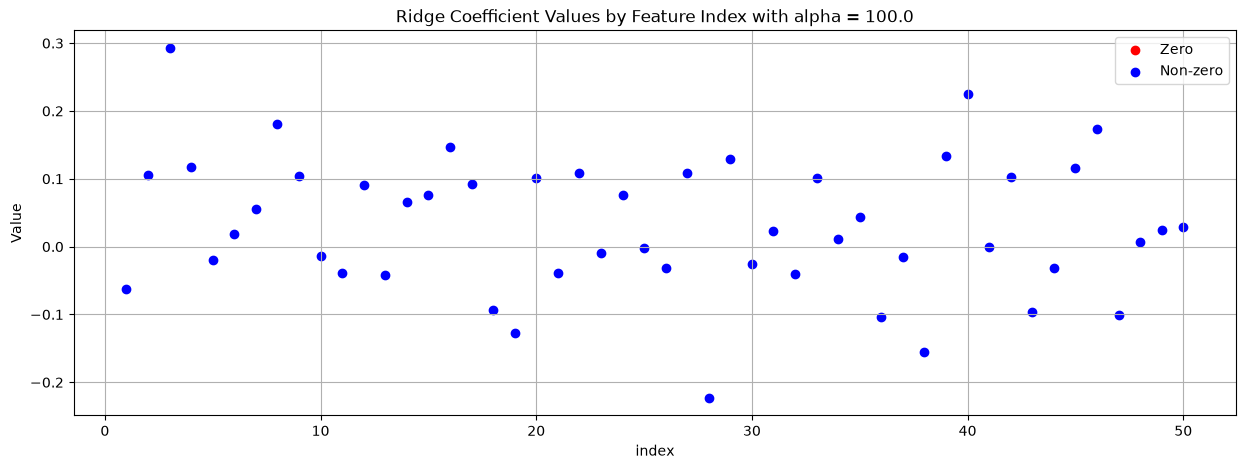

In [41]:
Ridge_models = run_ridge(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

### Ridge Best Alpha

MAE: 0.02
MSE: 0.00
RMSE: 0.02
R² Score: 1.00
Number of non zero coefs: 50
Max coef magnitude: 1.8456
Mean coef magnitude: 0.1860


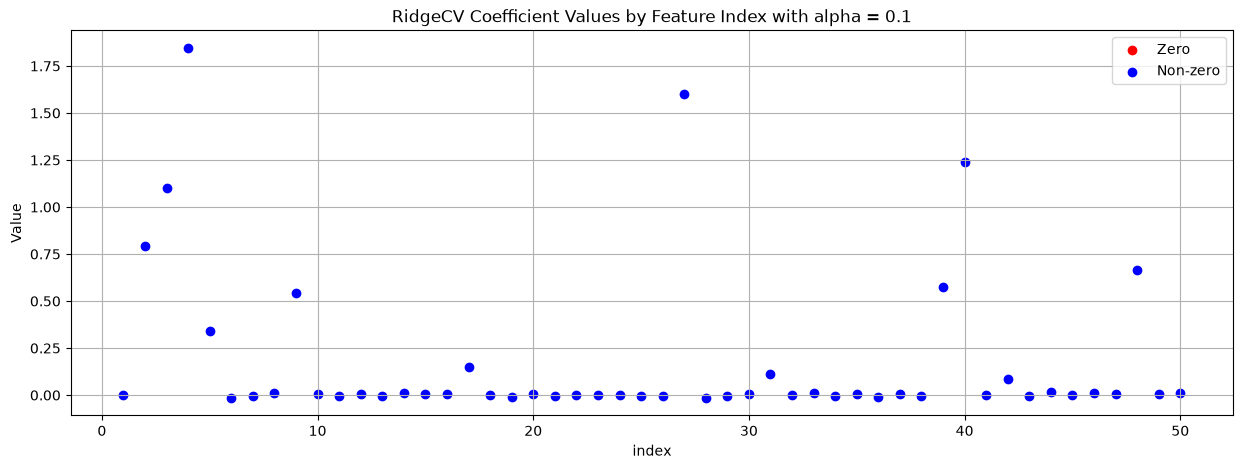

In [42]:
RidgeCV_model = run_ridge_cv(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

## 5. Elastic Net

Metrics for i = 0.001:
MAE: 0.01
MSE: 0.00
RMSE: 0.01
R² Score: 1.00
Number of non zero coefs: 25
Max coef magnitude: 1.8676
Mean coef magnitude: 0.1826


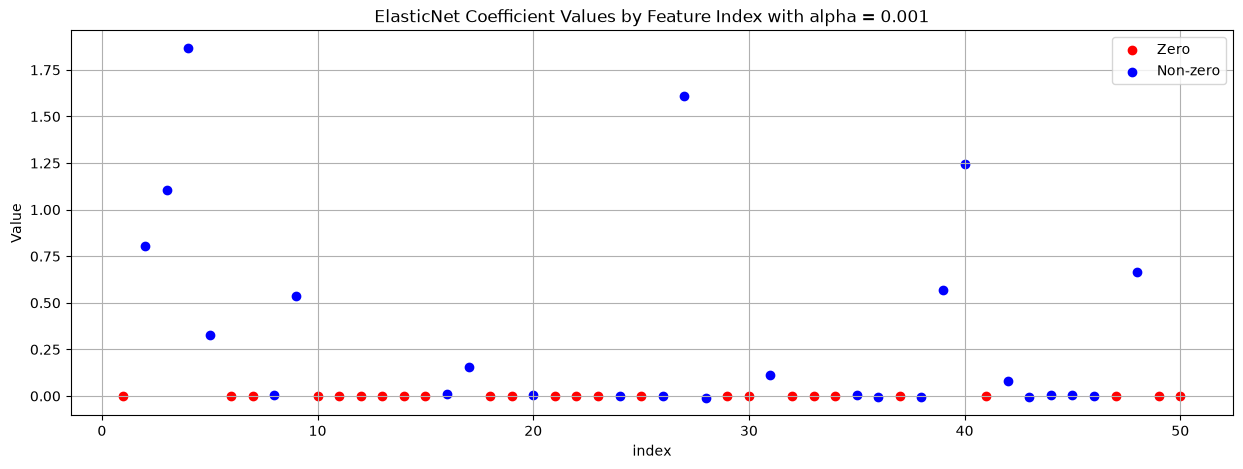

Metrics for i = 0.01:
MAE: 0.09
MSE: 0.01
RMSE: 0.11
R² Score: 1.00
Number of non zero coefs: 25
Max coef magnitude: 1.6511
Mean coef magnitude: 0.1647


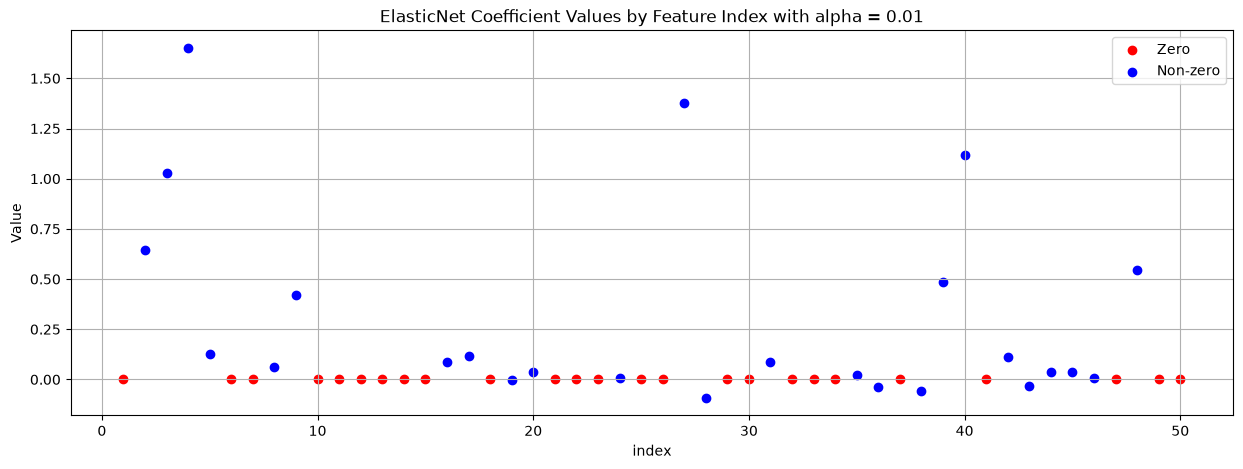

Metrics for i = 0.1:
MAE: 0.43
MSE: 0.30
RMSE: 0.55
R² Score: 0.92
Number of non zero coefs: 22
Max coef magnitude: 0.7374
Mean coef magnitude: 0.0886


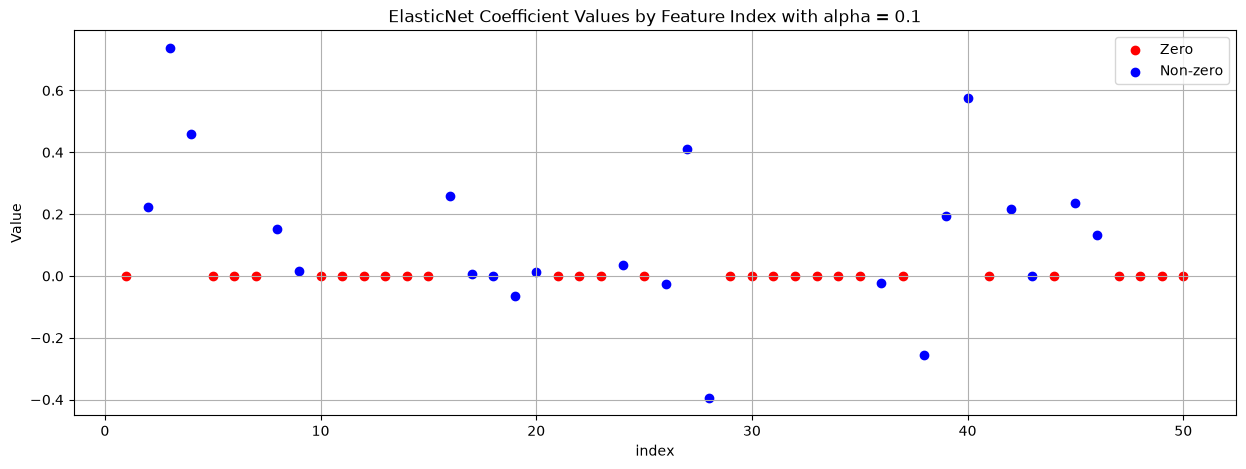

Metrics for i = 1.0:
MAE: 0.91
MSE: 1.43
RMSE: 1.20
R² Score: 0.64
Number of non zero coefs: 11
Max coef magnitude: 0.3117
Mean coef magnitude: 0.0319


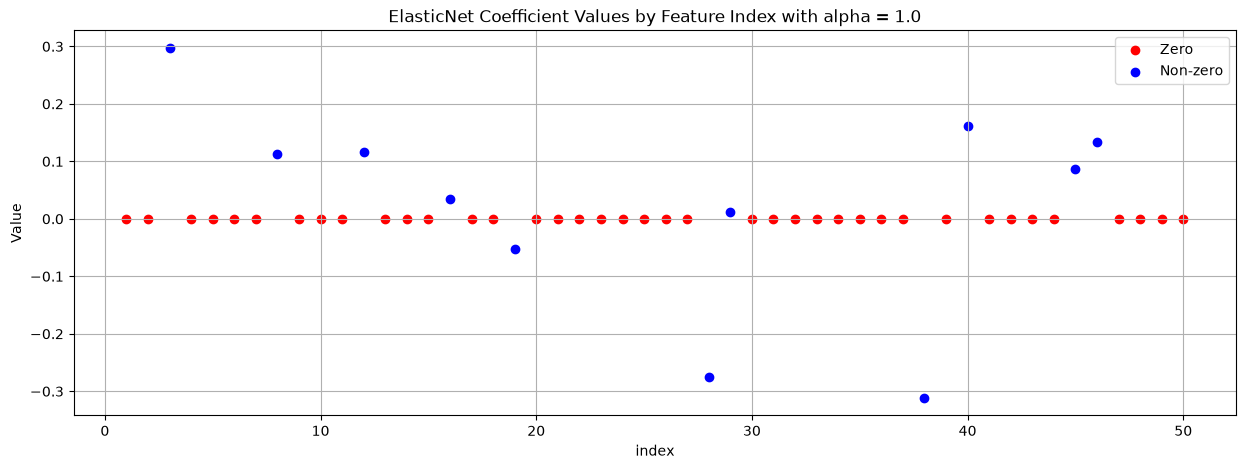

Metrics for i = 10.0:
MAE: 1.55
MSE: 4.41
RMSE: 2.10
R² Score: -0.11
Number of non zero coefs: 0
Max coef magnitude: 0.0000
Mean coef magnitude: 0.0000


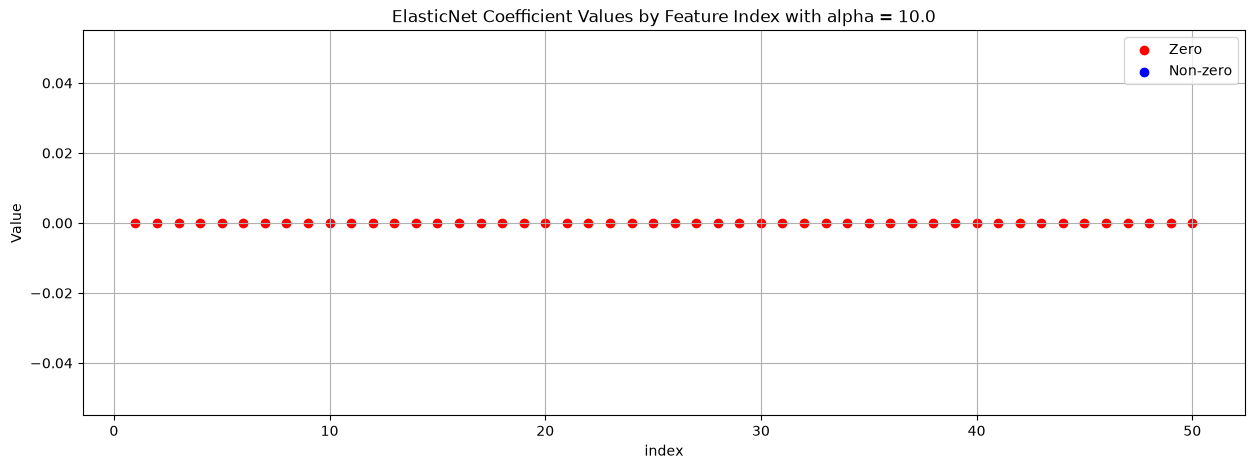

Metrics for i = 100.0:
MAE: 1.55
MSE: 4.41
RMSE: 2.10
R² Score: -0.11
Number of non zero coefs: 0
Max coef magnitude: 0.0000
Mean coef magnitude: 0.0000


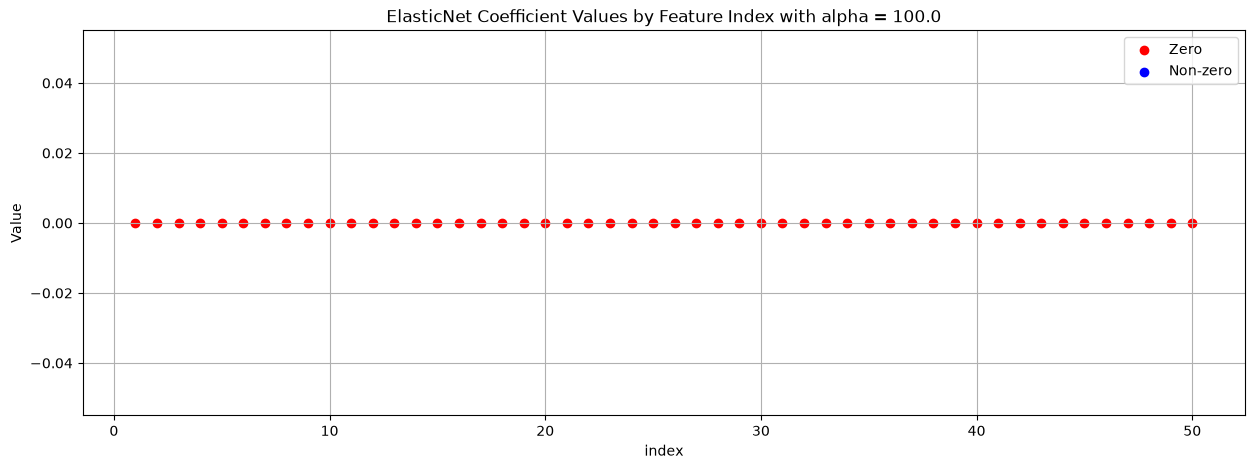

In [43]:
ElasticNet_alpha_models = run_elasticnet_alpha(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

Metrics for i = 0.0:
MAE: 0.61
MSE: 0.56
RMSE: 0.75
R² Score: 0.86
Number of non zero coefs: 50
Max coef magnitude: 0.2725
Mean coef magnitude: 0.0794


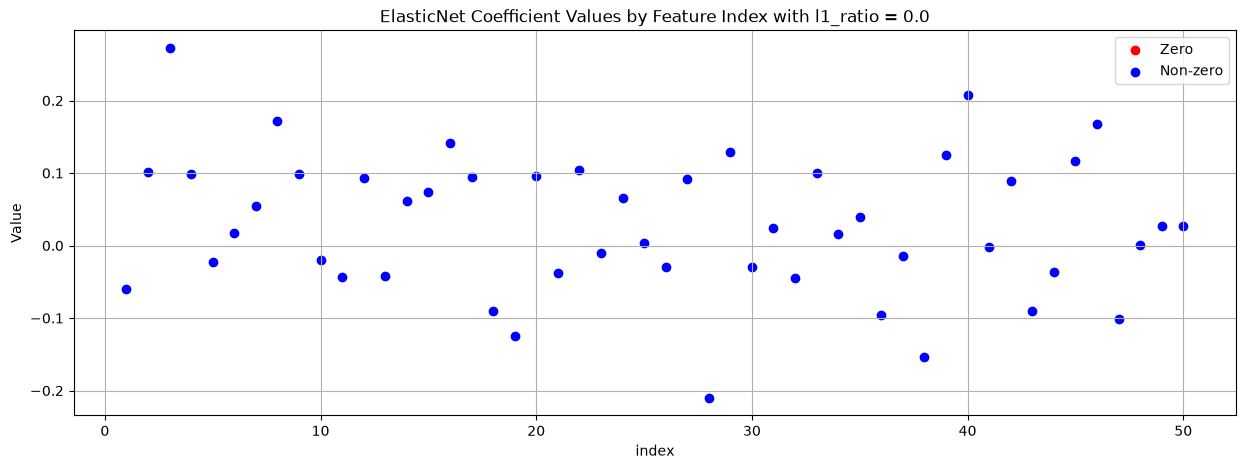

Metrics for i = 0.25:
MAE: 0.75
MSE: 0.96
RMSE: 0.98
R² Score: 0.76
Number of non zero coefs: 17
Max coef magnitude: 0.3172
Mean coef magnitude: 0.0427


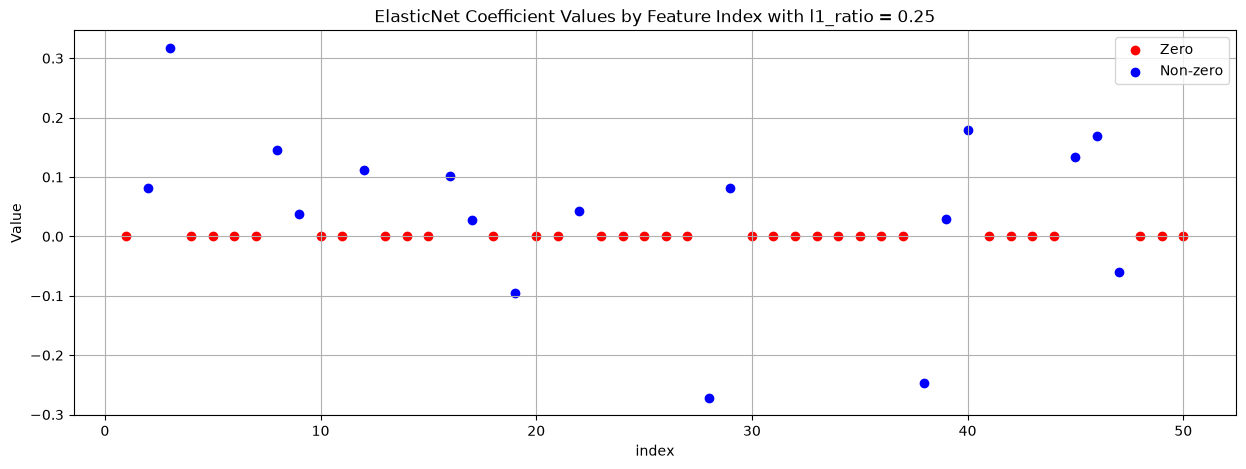

Metrics for i = 0.5:
MAE: 0.91
MSE: 1.43
RMSE: 1.20
R² Score: 0.64
Number of non zero coefs: 11
Max coef magnitude: 0.3117
Mean coef magnitude: 0.0319


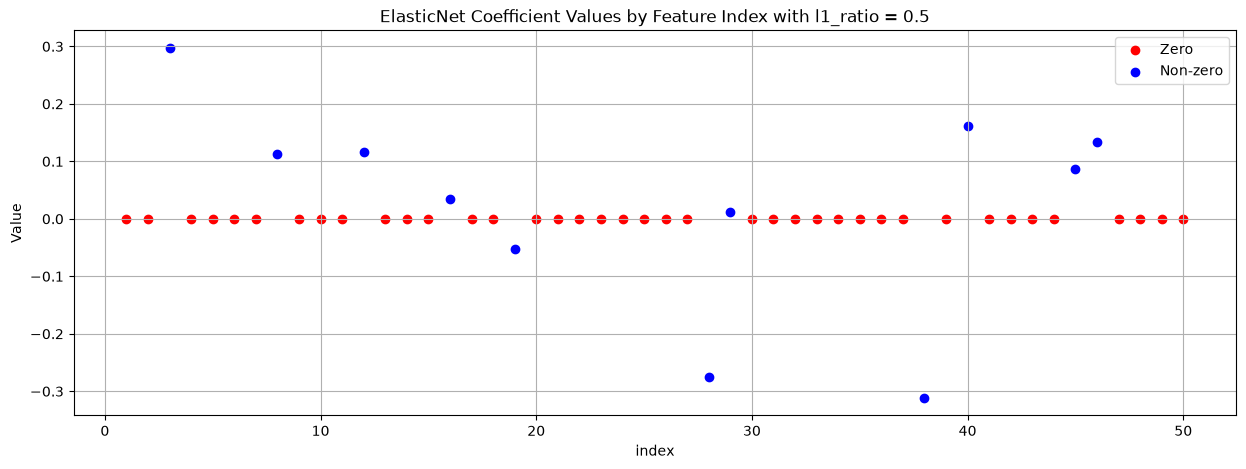

Metrics for i = 0.75:
MAE: 1.05
MSE: 1.93
RMSE: 1.39
R² Score: 0.52
Number of non zero coefs: 7
Max coef magnitude: 0.3822
Mean coef magnitude: 0.0235


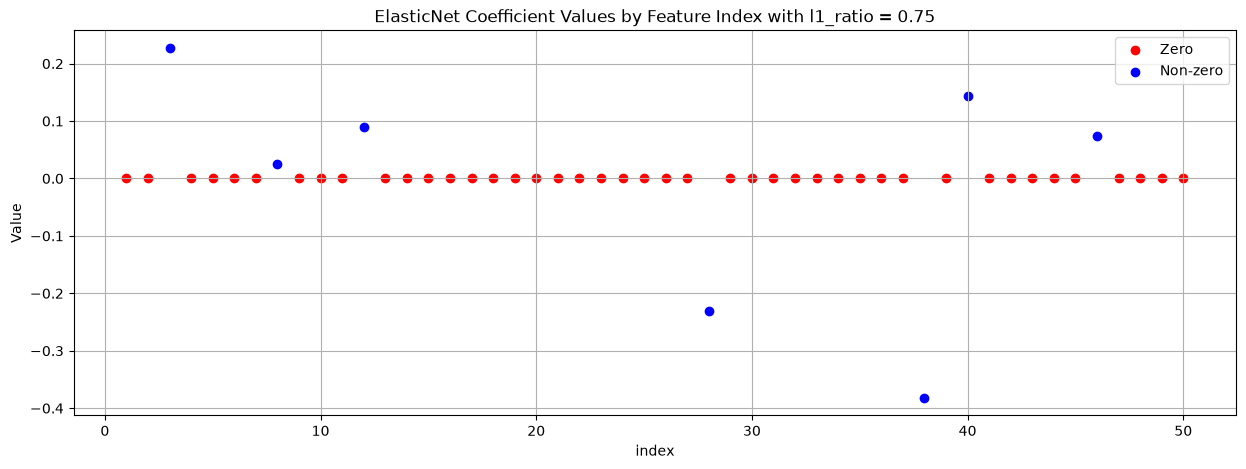

Metrics for i = 1.0:
MAE: 1.19
MSE: 2.49
RMSE: 1.58
R² Score: 0.37
Number of non zero coefs: 4
Max coef magnitude: 0.3883
Mean coef magnitude: 0.0163


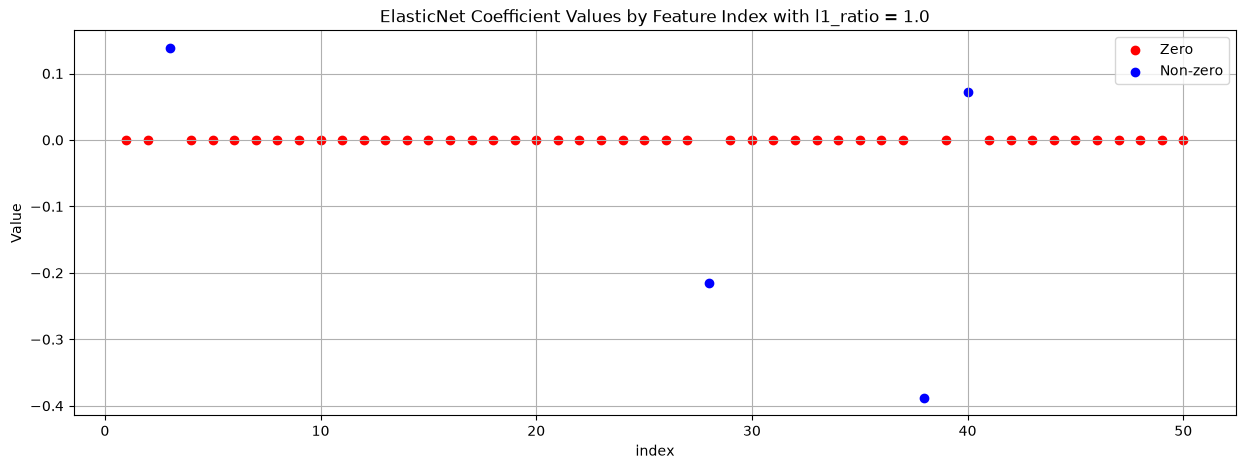

In [44]:
ElasticNet_l1_models = run_elasticnet_l1ratio(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

### Best alpha and l1 ratio for ElasticNet

MAE: 0.01
MSE: 0.00
RMSE: 0.02
R² Score: 1.00
Number of non zero coefs: 22
Max coef magnitude: 1.8702
Mean coef magnitude: 0.1813


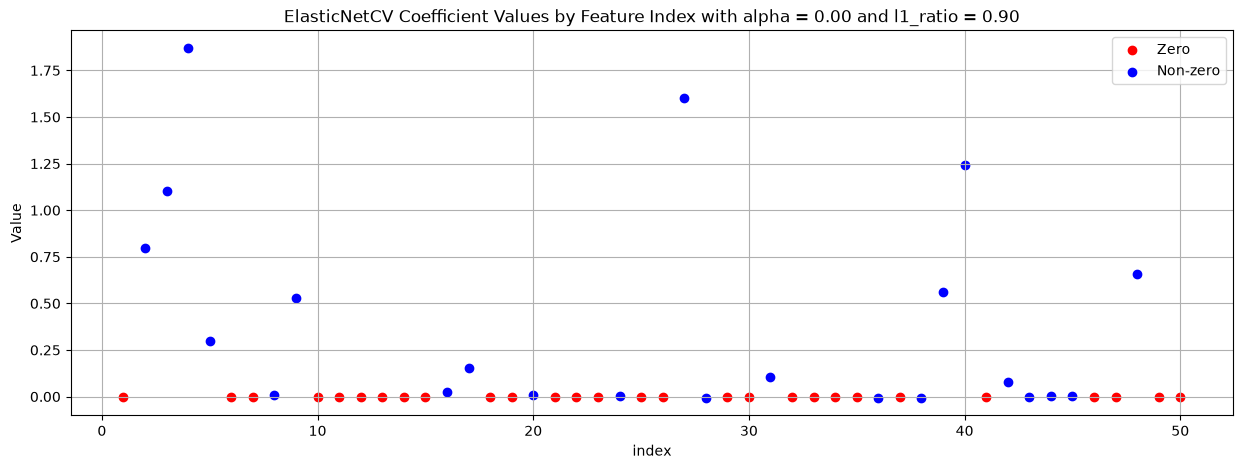

In [45]:
ElasticNet_model = run_elasticnet_cv(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)